In [90]:
import numpy as np
import pandas as pd

In [91]:
df=pd.read_csv('/content/audi.csv')

In [92]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,A1,2017,12500,Manual,15735,Petrol,150,55.4,1.4
1,A6,2016,16500,Automatic,36203,Diesel,20,64.2,2.0
2,A1,2016,11000,Manual,29946,Petrol,30,55.4,1.4
3,A4,2017,16800,Automatic,25952,Diesel,145,67.3,2.0
4,A3,2019,17300,Manual,1998,Petrol,145,49.6,1.0


In [93]:
df.shape

(101668, 9)

In [94]:
df.isnull().sum()

,0
model,0
year,0
price,0
transmission,0
mileage,0
fuelType,0
tax,0
mpg,0
engineSize,0


In [95]:
df['model'].value_counts()

,count
model,
A3,18349
Q3,13439
A4,13007
A1,12888
A5,8450
Q5,8283
Q2,7760
A6,7175
Q7,3865


In [96]:
df['year'].value_counts()

,count
year,
2019,30091
2016,19099
2017,18411
2015,9617
2018,8135
2020,6787
2014,4330
2013,2807
2012,797


In [97]:
X = df.drop('price', axis=1)
y = df['price']

In [98]:
X = pd.get_dummies(X, drop_first=True)

In [99]:
X

,year,mileage,tax,mpg,engineSize,model_A2,model_A3,model_A4,model_A5,model_A6,...,model_S4,model_S5,model_S8,model_SQ5,model_SQ7,model_TT,transmission_Manual,transmission_Semi-Auto,fuelType_Hybrid,fuelType_Petrol
0,2017,15735,150,55.4,1.4,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,True
1,2016,36203,20,64.2,2.0,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
2,2016,29946,30,55.4,1.4,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,True
3,2017,25952,145,67.3,2.0,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
4,2019,1998,145,49.6,1.0,False,True,False,False,False,...,False,False,False,False,False,False,True,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101663,2019,8085,145,33.0,2.0,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
101664,2015,37761,145,51.1,2.0,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
101665,2016,36271,145,57.1,2.0,False,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False
101666,2015,43862,145,69.6,2.0,False,True,False,False,False,...,False,False,False,False,False,False,True,False,False,False


In [100]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [101]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [102]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
y_mean = y_train.mean()
y_std = y_train.std()
y_train_scaled = ((y_train - y_mean) / y_std).to_numpy()
y_test_scaled = ((y_test - y_mean) / y_std).to_numpy()

In [103]:
def loss_function(y,y_pred):
    return np.mean((y_pred - y) ** 2)

In [104]:
def sgd_with_replacement(X,y,batch_size,lr=0.001,epochs=100):
    n_samples,n_features = X.shape
    rng = np.random.default_rng()
    w = np.zeros(n_features)
    b = 0
    loss_history = []
    for epoch in range(epochs):
        num_updates = int(np.ceil(n_samples / batch_size))
        for _ in range(num_updates):
            indices = rng.choice(n_samples, size=batch_size, replace=True)
            X_batch = X[indices]
            y_batch = y[indices]
            y_pred = np.dot(X_batch,w) + b
            error = y_pred - y_batch
            dw = (2 / len(y_batch))*np.dot(X_batch.T,error)
            db = 2 * np.mean(error)
            w = w - lr*dw
            b = b - lr*db
        predictions = np.dot(X,w) + b
        epoch_mse = loss_function(y, predictions)
        loss_history.append(epoch_mse)
    return w,b,loss_history

In [105]:
def sgd_without_replacement(X, y, batch_size, lr=0.001, epochs=100):
    n_samples, n_features = X.shape
    rng = np.random.default_rng()
    w = np.zeros(n_features)
    b = 0.0
    loss_history = []
    for epoch in range(epochs):
        indices = rng.permutation(n_samples)
        for start in range(0, n_samples, batch_size):
            batch_indices = indices[start:start + batch_size]
            X_batch = X[batch_indices]
            y_batch = y[batch_indices]
            y_pred = np.dot(X_batch, w) + b
            error = y_pred - y_batch
            dw = (2 / len(y_batch)) * np.dot(X_batch.T, error)
            db = 2 * np.mean(error)
            w = w - lr*dw
            b = b - lr*db
        predictions = np.dot(X, w) + b
        epoch_mse = loss_function(y, predictions)
        loss_history.append(epoch_mse)
    return w,b,loss_history

In [106]:
batch_sizes = [16, 32, 64, 128, 256]
epochs = 100
lr = 0.001

results = []
histories = {}

for batch_size in batch_sizes:

    # Strategy 1: With replacement
    w1, b1, loss1 = sgd_with_replacement(
        X_train, y_train_scaled,
        batch_size=batch_size,
        lr=lr, epochs=epochs
    )

    histories[(batch_size, "With replacement")] = loss1

    results.append({
        "Batch Size": batch_size,
        "Strategy": "With replacement",
        "Final Training MSE": loss1[-1]
    })

    # Strategy 2: Without replacement
    w2, b2, loss2 = sgd_without_replacement(
        X_train, y_train_scaled,
        batch_size=batch_size,
        lr=lr, epochs=epochs
    )

    histories[(batch_size, "Without replacement")] = loss2

    results.append({
        "Batch Size": batch_size,
        "Strategy": "Without replacement",
        "Final Training MSE": loss2[-1]
    })

results_df = pd.DataFrame(results)
print(results_df)

   Batch Size             Strategy  Final Training MSE
0          16     With replacement       2.372202e+149
1          16  Without replacement       6.118907e+147
2          32     With replacement        1.410540e-01
3          32  Without replacement        1.409877e-01
4          64     With replacement        1.412815e-01
5          64  Without replacement        1.403546e-01
6         128     With replacement        1.404382e-01
7         128  Without replacement        1.403005e-01
8         256     With replacement        1.403500e-01
9         256  Without replacement        1.402828e-01


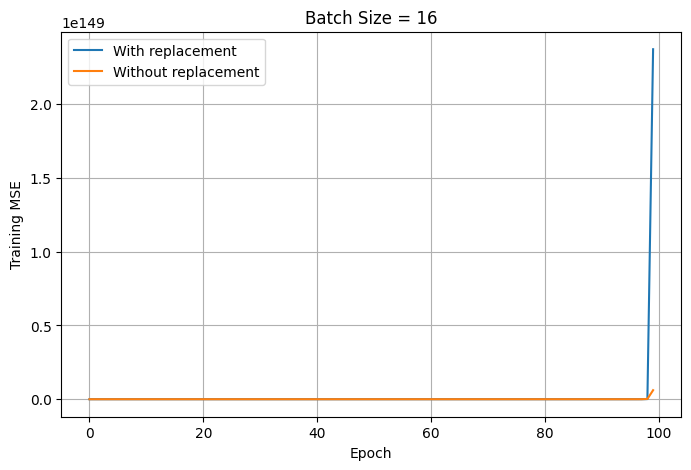

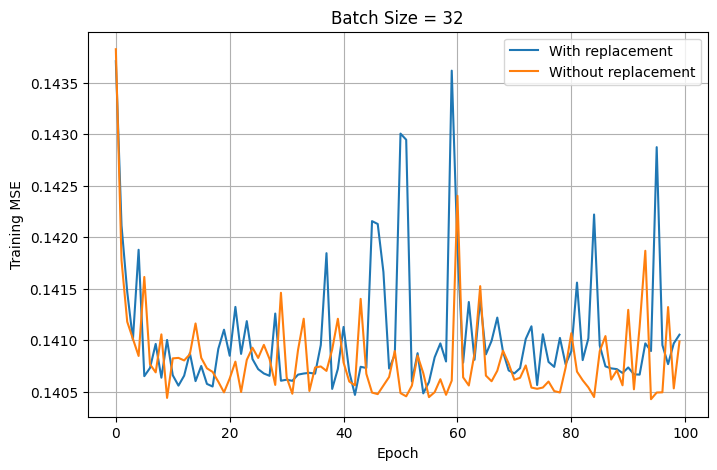

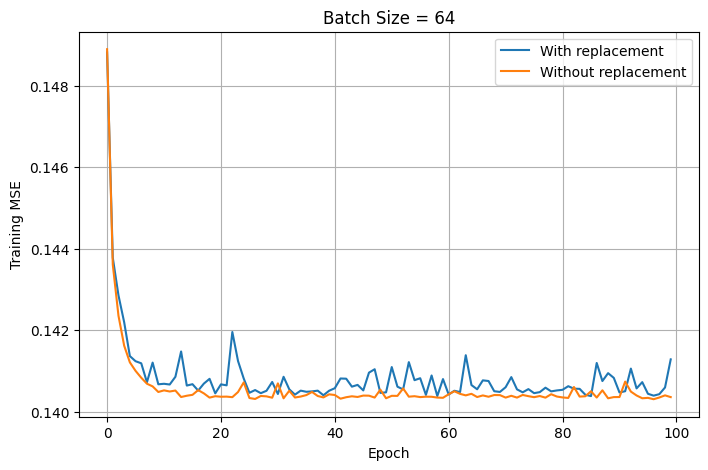

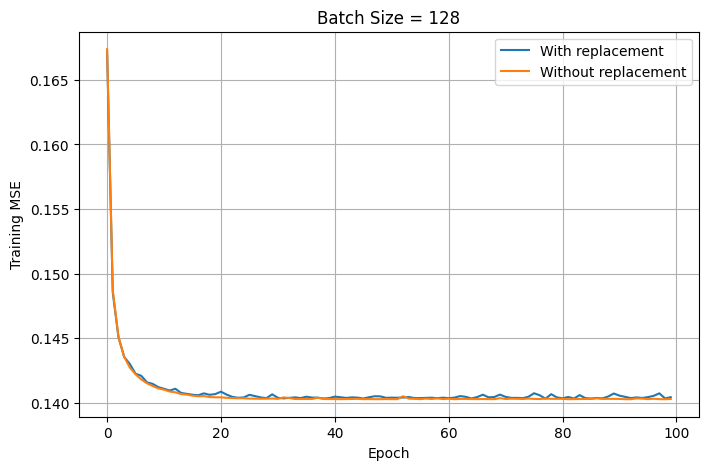

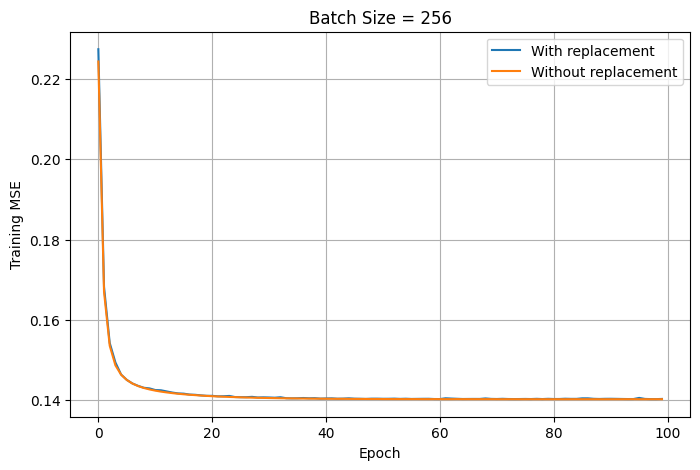

In [107]:
import matplotlib.pyplot as plt

for batch_size in batch_sizes:
    plt.figure(figsize=(8, 5))
    plt.plot(
        histories[(batch_size, "With replacement")],
        label="With replacement"
    )
    plt.plot(
        histories[(batch_size, "Without replacement")],
        label="Without replacement"
    )
    plt.xlabel("Epoch")
    plt.ylabel("Training MSE")
    plt.title(f"Batch Size = {batch_size}")
    plt.legend()
    plt.grid(True)
    plt.show()

In [108]:
best_result = results_df.loc[
    results_df["Final Training MSE"].idxmin()
]

print("Best configuration:")
print(best_result)

Best configuration:
Batch Size                            256
Strategy              Without replacement
Final Training MSE               0.140283
Name: 9, dtype: object
